In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

Isooctane samples 20mM for different w0
   1. 20 mM TEMPO-SO4 RM, w0 = 20 VTU at 283K
   2. 20 mM TEMPO-SO4 RM, w0 = 30 room temperature 231121 data 

In [2]:
d1 = find_file("240220_TempoSO4_W20_run1.DSC", exp_type="francklab_esr/romana") # w20 
d2 = find_file("231121_20mMTEMPOSO4_W30.DSC", exp_type="francklab_esr/romana") # w30

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(3413, '$B_0$'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(3413, '$B_0$'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ Isooctane for cooling')

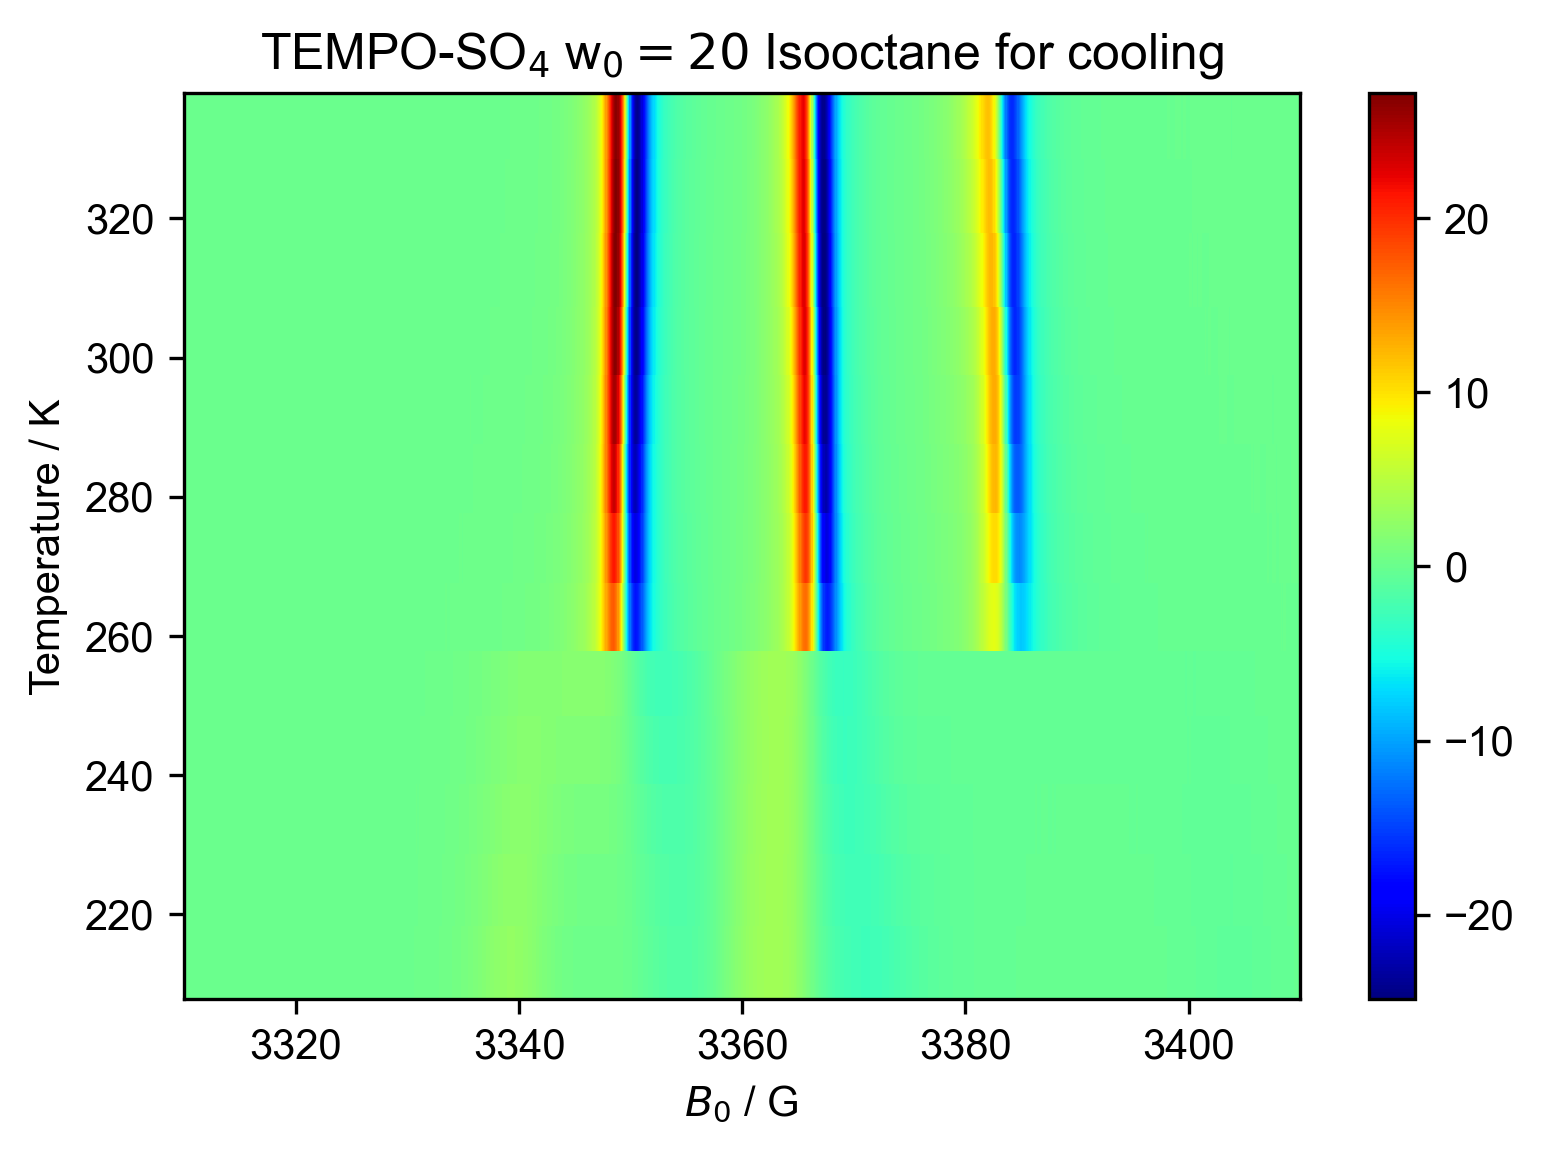

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ Isooctane for cooling")

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
# d2.sort('Temperature')
# d2.reorder("Temperature").pcolor()
# title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling")

<Figure size 1800x1200 with 0 Axes>

From this, I learn that
it's easiest to show the 1D plots above and below the transition

[213.015 223.572 233.628 243.757 253.058 262.649 272.655 282.521 292.595
 302.373 312.024 323.717 333.239]


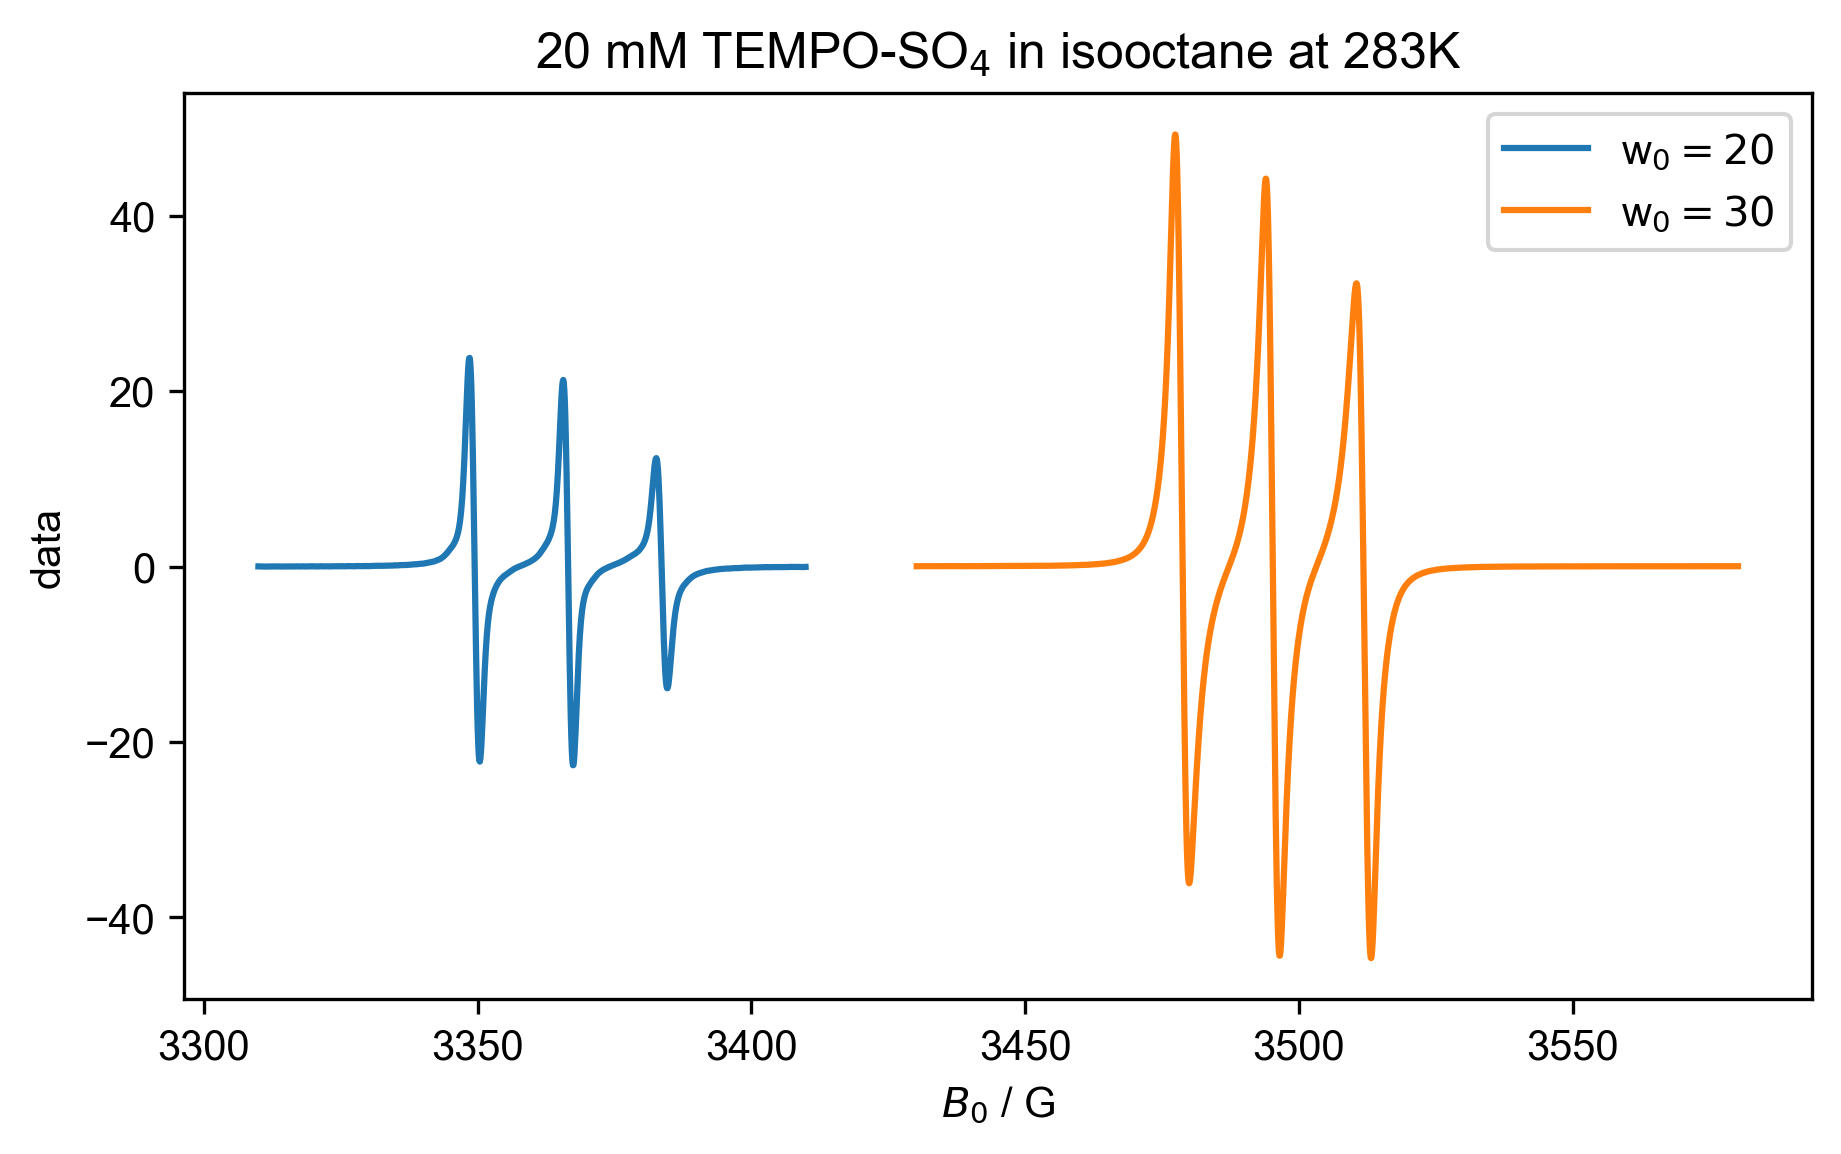

In [9]:
#near room temperature
print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":283], label="w$_0= 20$")
plot(d2, label="w$_0= 30$")
title("20 mM TEMPO-SO$_4$ in isooctane at 283K")
legend()

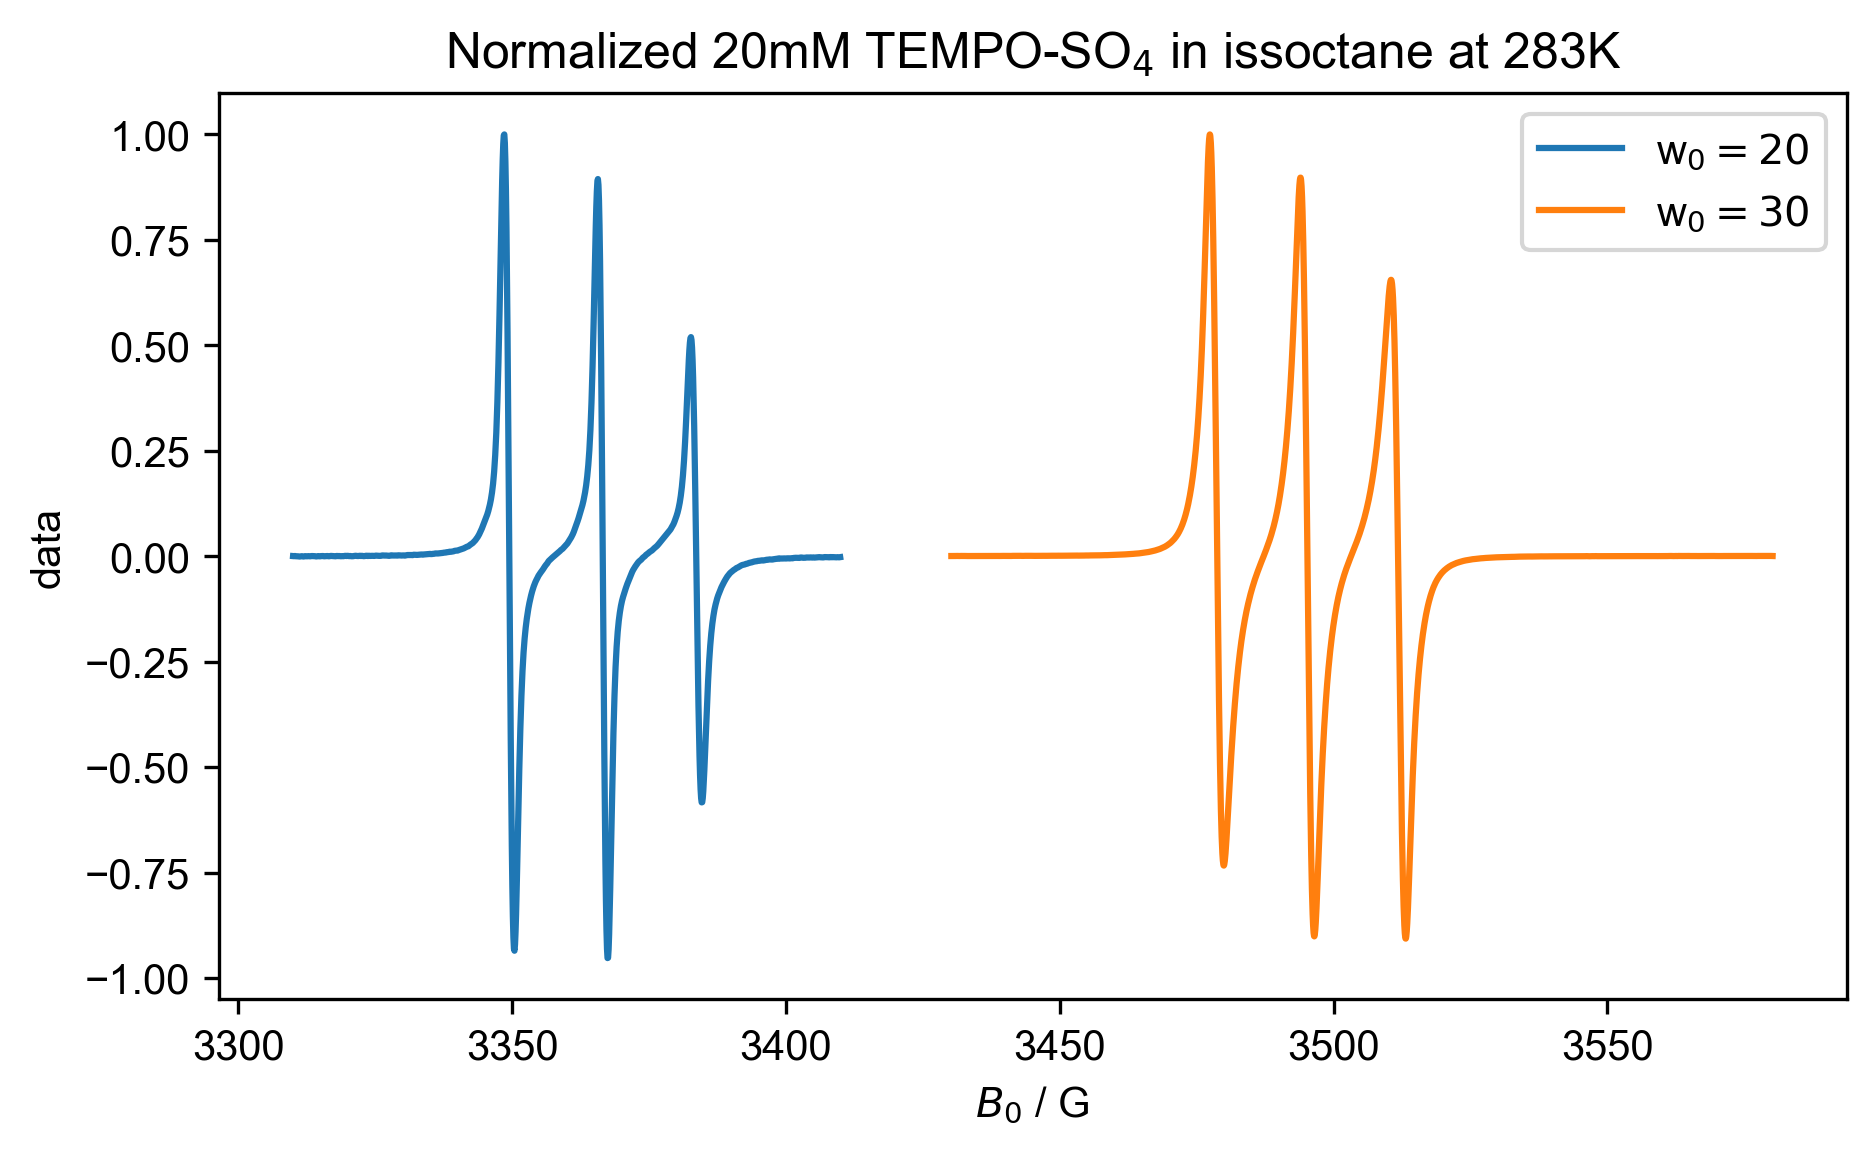

In [10]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "w$_0= 20$")
plot(d2 / d2.max(), label= "w$_0= 30$")
title("Normalized 20mM TEMPO-SO$_4$ in issoctane at 283K")
legend()

In [11]:
# hall probe correction
d1['$B_0$'] *= 1.0001 # W20
d2['$B_0$'] *= 1.0006 # W30

d1['$B_0$'] -= d1.get_prop('MWFQ')/gammabar_e*1e4
d2['$B_0$'] -= d2.get_prop('MWFQ')/gammabar_e*1e4

[213.015 223.572 233.628 243.757 253.058 262.649 272.655 282.521 292.595
 302.373 312.024 323.717 333.239]


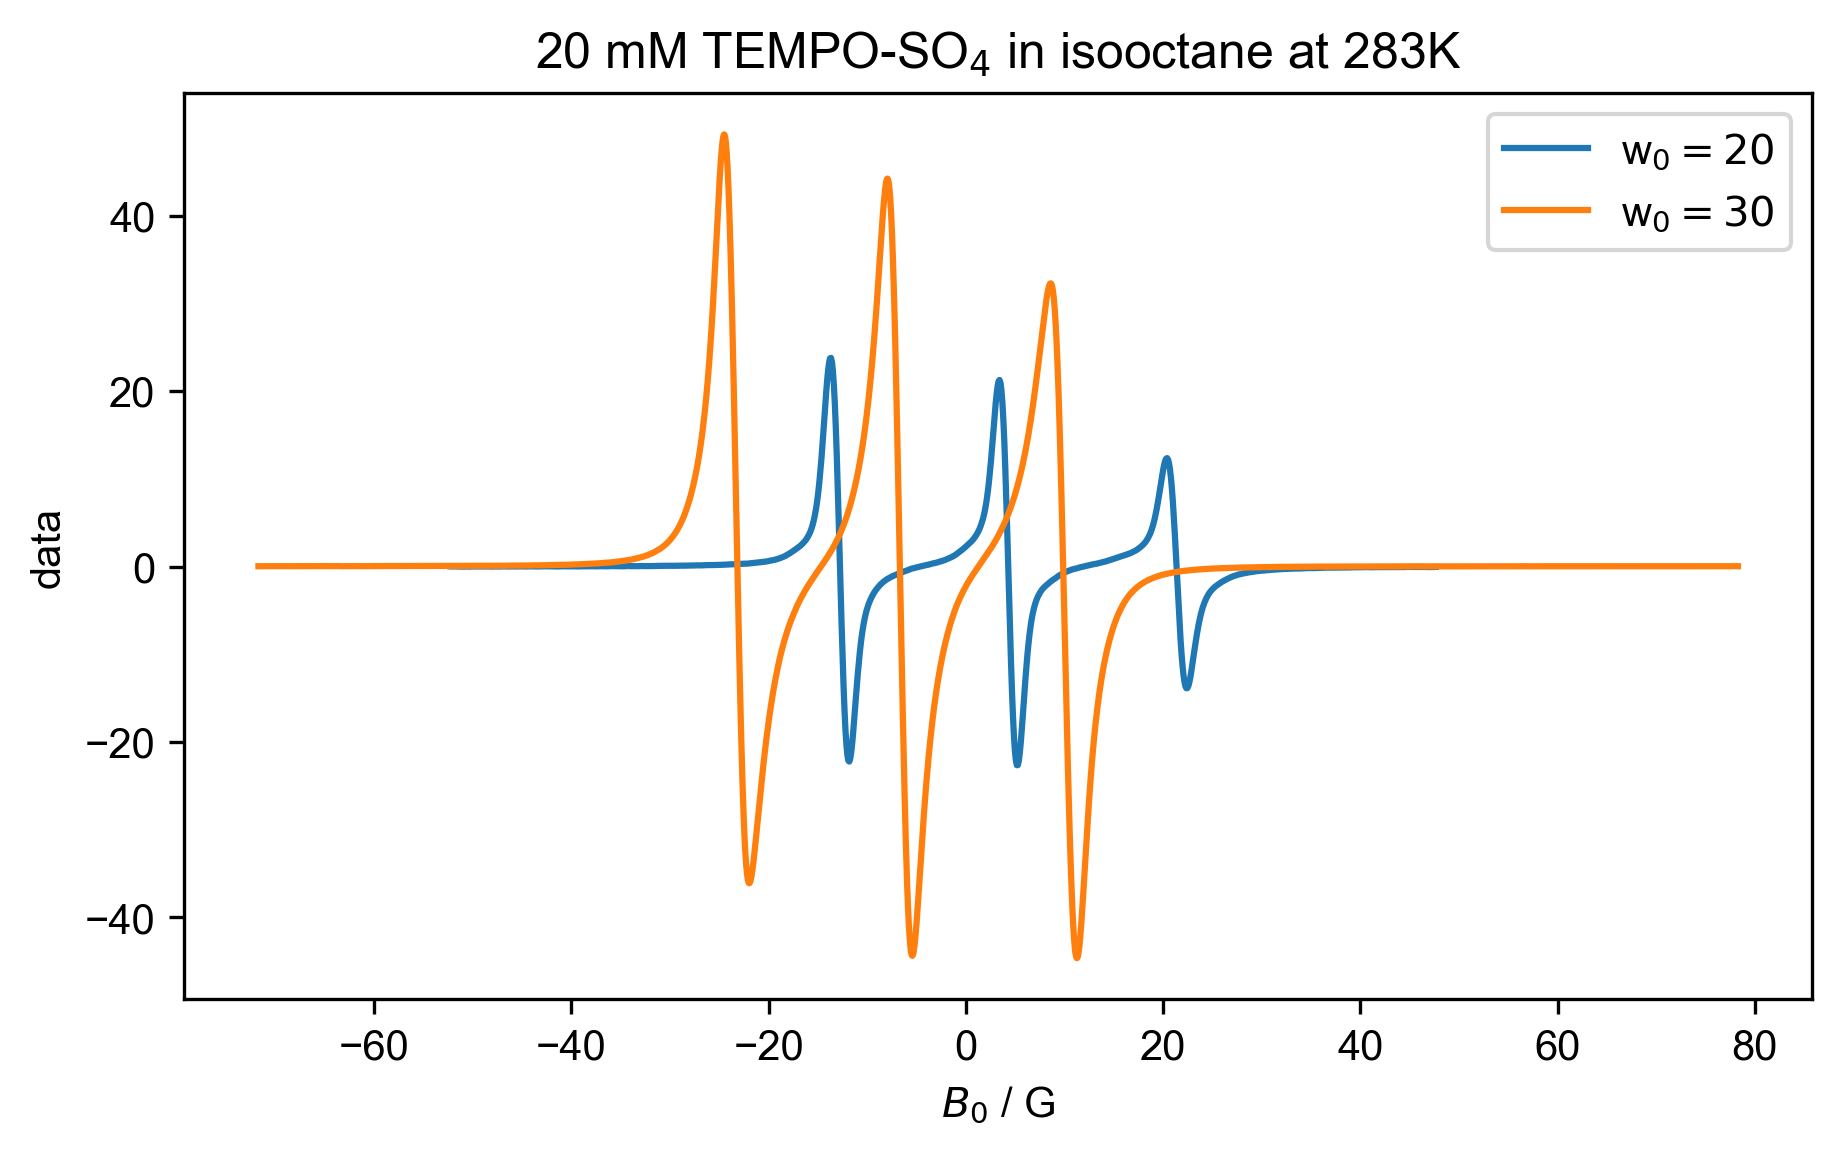

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":283], label="w$_0= 20$")
plot(d2, label="w$_0= 30$")
title("20 mM TEMPO-SO$_4$ in isooctane at 283K")
legend()

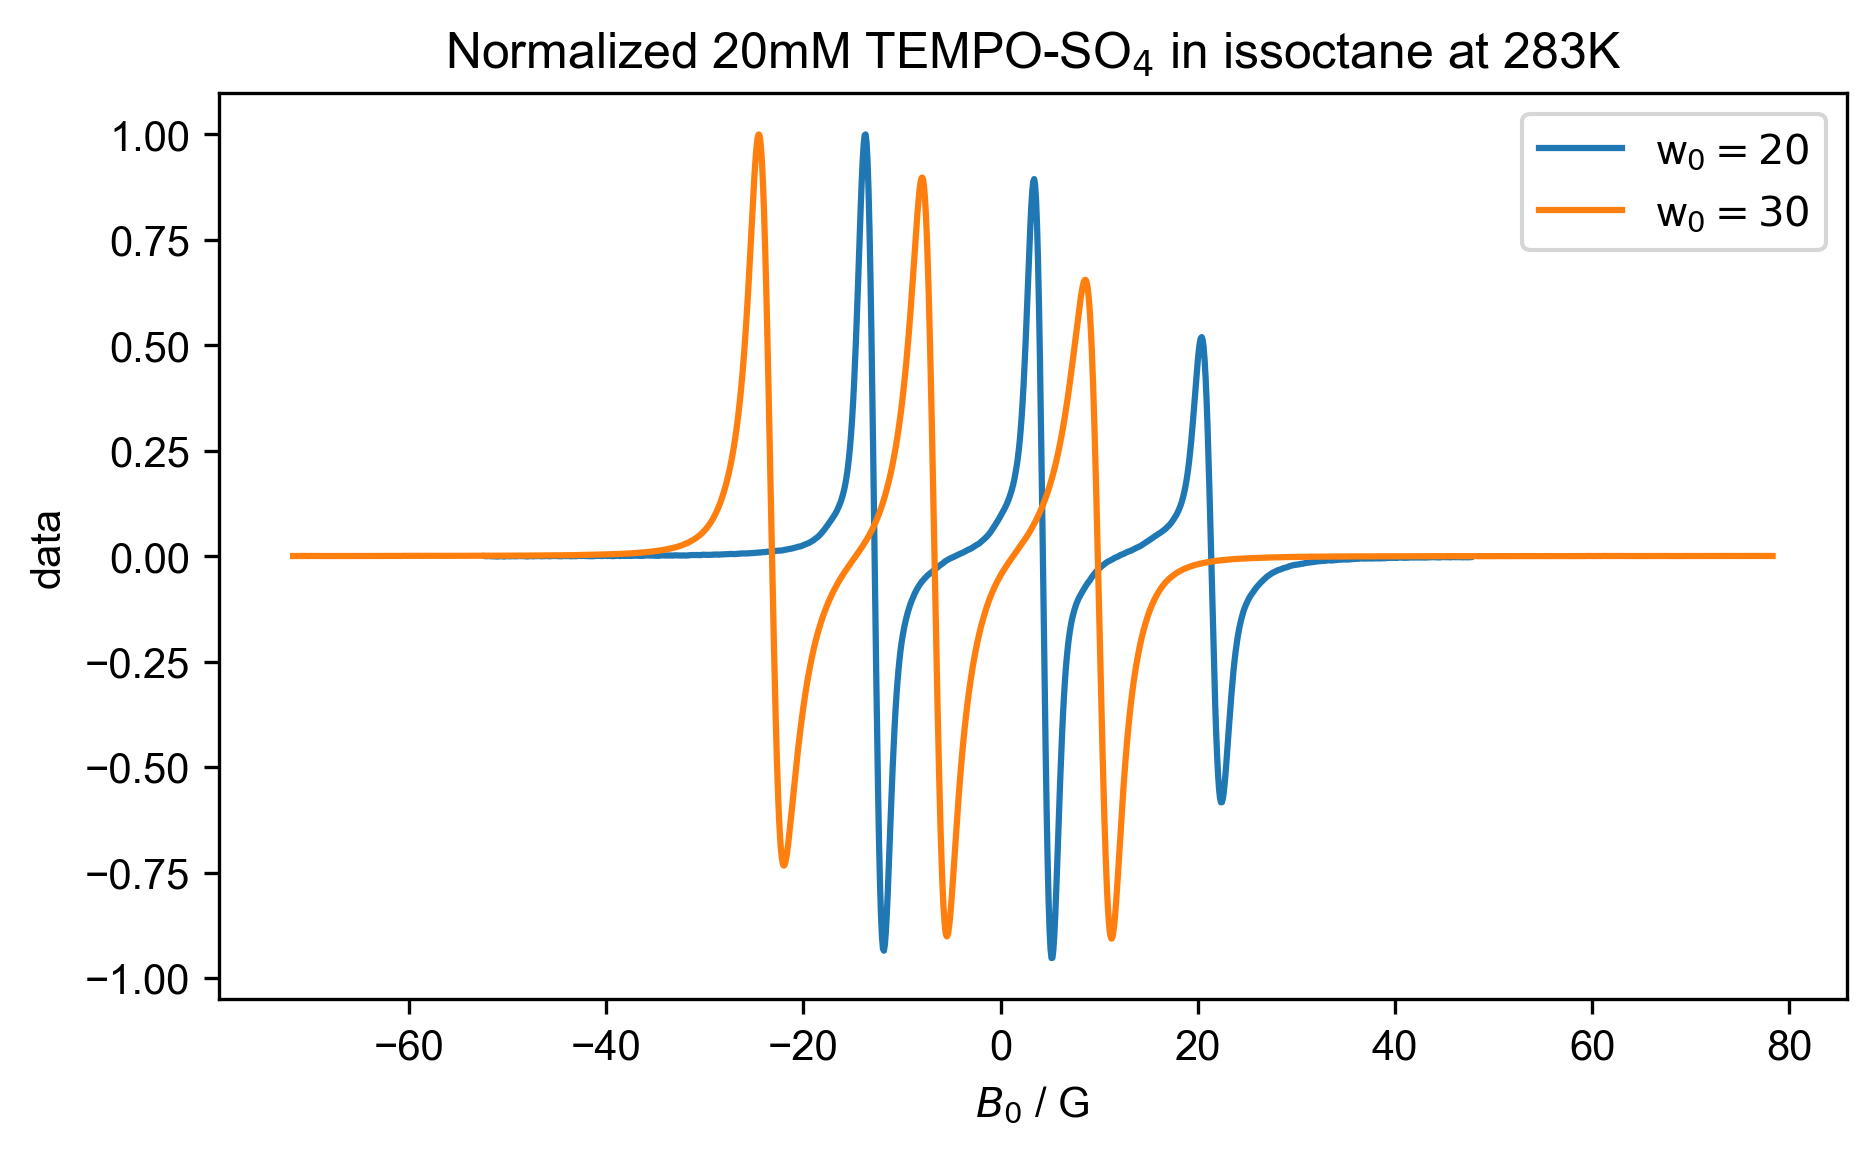

In [13]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "w$_0= 20$")
plot(d2 / d2.max(), label= "w$_0= 30$")
title("Normalized 20mM TEMPO-SO$_4$ in issoctane at 283K")
legend()